<a href="https://colab.research.google.com/github/omarsameh310/labs/blob/main/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import cv2, time
import numpy as np
import matplotlib.pyplot as plt

img  = cv2.imread('/content/photo.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)

print(gray.shape)



(220, 331)


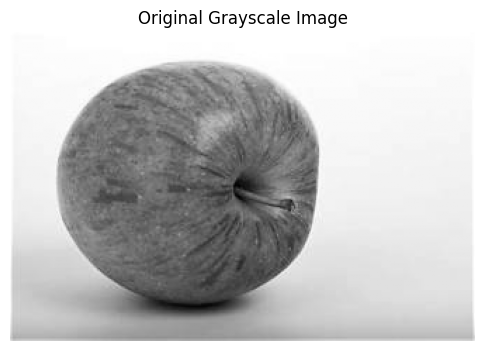

In [11]:
plt.figure(figsize=(6, 6))
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()



In [12]:
# adds random intensity variations to pixels
def add_gaussian_noise(g, sigma=15):
    return np.clip(g + np.random.normal(0, sigma, g.shape), 0, 255)

# randomly changes some pixels to black (0) or white (255).
def add_salt_pepper(g, p=0.05):
    out = g.copy();
    r = np.random.rand(*g.shape)
    out[r < p/2] = 0;
    out[r > 1 - p/2] = 255
    return out


In [13]:
def my_convolve(image, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(image, ((ph, ph), (pw, pw)))
    out = np.zeros_like(image)
    k = np.flip(kernel)              # true convolution flips the kernel
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i+kh, j:j+kw]
            out[i, j] = np.sum(region * k)   # multiply-and-sum
    return out


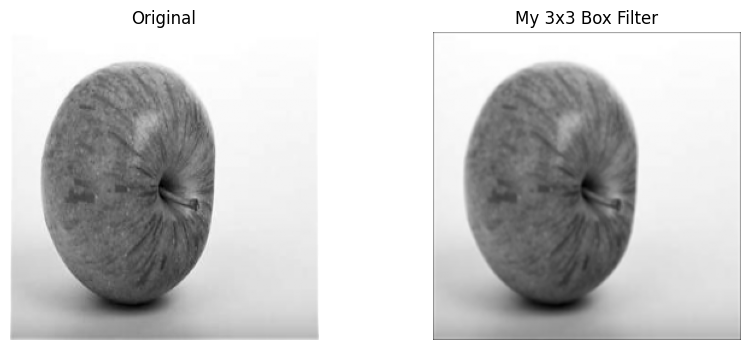

In [14]:
box_kernel = np.ones((3, 3), dtype=np.float64) / 9
small = cv2.resize(gray, (256, 256))
my_result = my_convolve(small, box_kernel)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(small, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(my_result, cmap='gray')
plt.title("My 3x3 Box Filter")
plt.axis('off')

plt.show()


In [15]:
cv_result = cv2.filter2D(
    small,
    ddepth=-1, # keep the same data type as the input image
    kernel=box_kernel,
    borderType=cv2.BORDER_CONSTANT  # padding with zero
)

diff = np.abs(my_result - cv_result)

print("Maximum absolute difference:")
print(np.max(diff)) # the worst mismatch between the two implementations

Maximum absolute difference:
5.684341886080802e-14


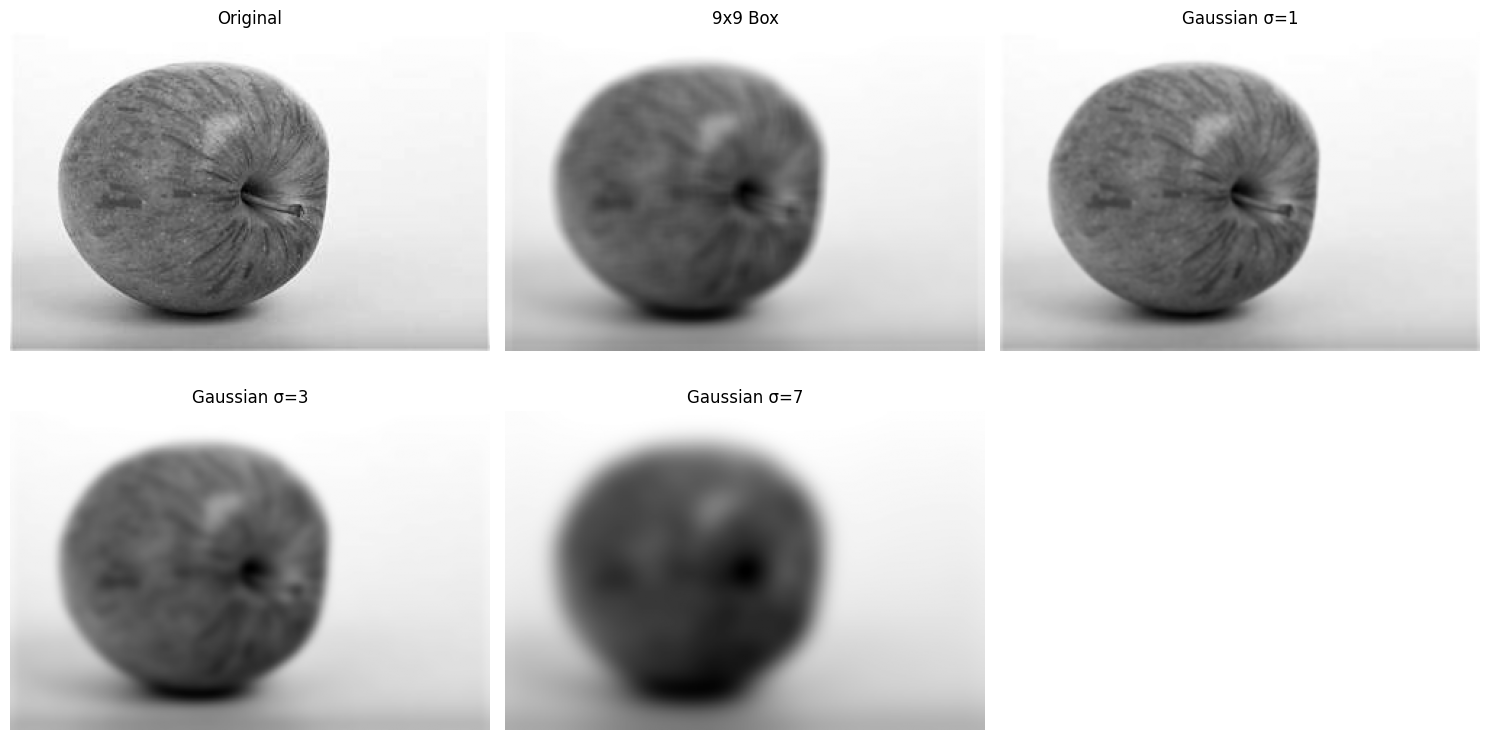

In [16]:
box9 = cv2.blur( gray, (9, 9) )
gauss1 = cv2.GaussianBlur(gray, (0, 0), 1)
gauss3 = cv2.GaussianBlur(gray, (0, 0), 3)
gauss7 = cv2.GaussianBlur(gray, (0, 0), 7)

plt.figure(figsize=(15, 8))

images = [
    gray,
    box9,
    gauss1,
    gauss3,
    gauss7
]

titles = [
    "Original",
    "9x9 Box",
    "Gaussian σ=1",
    "Gaussian σ=3",
    "Gaussian σ=7"
]

for i in range(len(images)):

    plt.subplot(2, 3, i + 1)

    plt.imshow(images[i], cmap='gray')

    plt.title(titles[i])

    plt.axis('off')

plt.tight_layout()
plt.show()



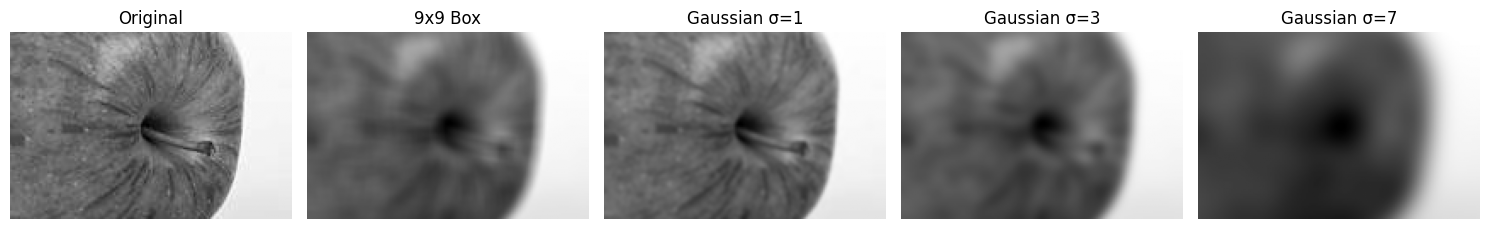

In [17]:
h, w = gray.shape

y1 = h // 4
y2 = 3 * h // 4

x1 = w // 4
x2 = 3 * w // 4

plt.figure(figsize=(15, 4))

for i in range(len(images)):

    crop = images[i][y1:y2, x1:x2]

    plt.subplot(1, 5, i + 1)

    plt.imshow(crop, cmap='gray')

    plt.title(titles[i])

    plt.axis('off')

plt.tight_layout()
plt.show()


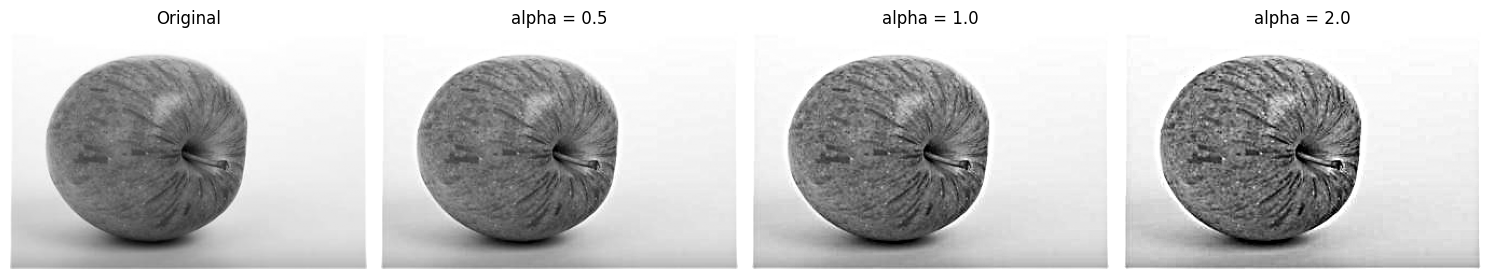

In [18]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original")
plt.axis('off')
blur  = cv2.GaussianBlur(gray, (0, 0), 3)
for i,a in enumerate([0.5, 1.0, 2.0]):
    sharp = np.clip(gray + a * (gray - blur), 0, 255)
    plt.subplot(1, 4, i + 2)
    plt.imshow(sharp, cmap='gray')
    plt.title(f"alpha = {a}")
    plt.axis('off')
    # display each result with its alpha
# sharp=original+α(original−blur)


plt.tight_layout()
plt.show()


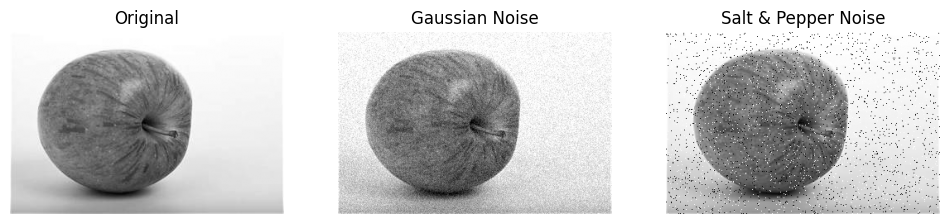

In [19]:
gaussian_noisy = add_gaussian_noise( gray,sigma=15)

sp_noisy = add_salt_pepper(gray,p=0.05)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noise")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sp_noisy, cmap='gray')
plt.title("Salt & Pepper Noise")
plt.axis('off')

plt.show()

In [20]:
# a Gaussian Blur
gaussian_gauss = cv2.GaussianBlur( gaussian_noisy,(0, 0),2)

sp_gauss = cv2.GaussianBlur( sp_noisy, (0, 0),  2)

#b Median Filter
gaussian_uint8 = gaussian_noisy.astype(np.uint8)
sp_uint8 = sp_noisy.astype(np.uint8)

gaussian_median = cv2.medianBlur(
    gaussian_uint8,
    5
) #kernel size=5 needs the image to be unit8

sp_median = cv2.medianBlur(
    sp_uint8,
    5
)


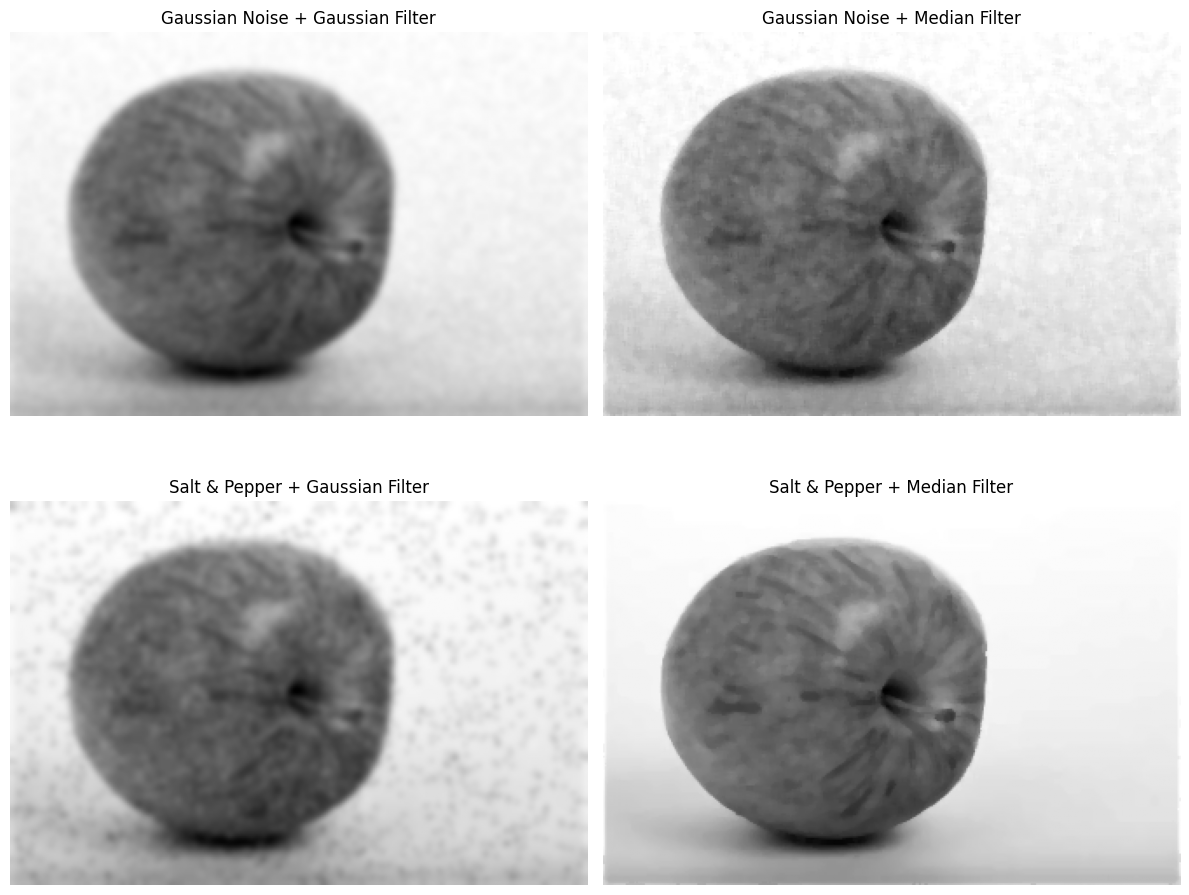

In [21]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_gauss, cmap='gray')
plt.title("Gaussian Noise + Gaussian Filter")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(gaussian_median, cmap='gray')
plt.title("Gaussian Noise + Median Filter")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sp_gauss, cmap='gray')
plt.title("Salt & Pepper + Gaussian Filter")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(sp_median, cmap='gray')
plt.title("Salt & Pepper + Median Filter")
plt.axis('off')

plt.tight_layout()
plt.show()
